In [3]:
print("Exploratory Data Analysis")

Exploratory Data Analysis


In [4]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

%matplotlib inline

In [5]:
filename = Path('../raw/default_of_credit_card_clients.xls')
data = pd.read_excel(filename, engine='calamine', skiprows=1)
df = data

In [6]:
df.to_csv('../raw/default_of_credit_card_clients.csv', index=False)

In [7]:
ds = pd.read_csv('../raw/default_of_credit_card_clients.csv')
df = ds

In [8]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [9]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [10]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='str')

In [11]:
df.shape

(30000, 25)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [13]:
df.isna().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [56]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='str')

In [15]:
df["default payment next month"].value_counts(normalize=True)

default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

<Axes: xlabel='default payment next month', ylabel='Count'>

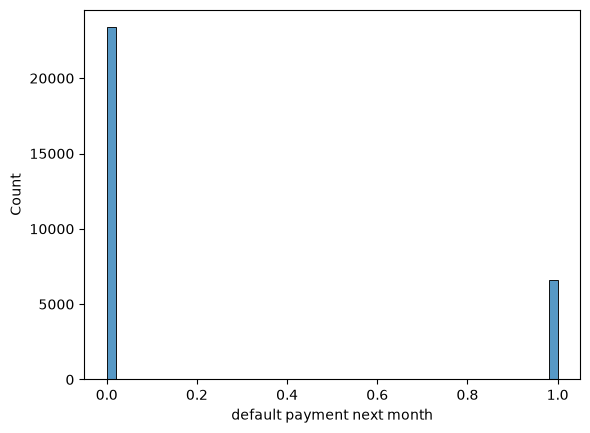

In [16]:
sns.histplot(df["default payment next month"], bins=50)

In [17]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [18]:
df.columns

Index(['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0',
       'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'default_payment_next_month'],
      dtype='str')

In [19]:
df["default_payment_next_month"].value_counts(normalize=True)

default_payment_next_month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [20]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [21]:
df['pay_0'].value_counts()

pay_0
 0    14737
-1     5686
 1     3688
-2     2759
 2     2667
 3      322
 4       76
 5       26
 8       19
 6       11
 7        9
Name: count, dtype: int64

In [22]:
categorical = [
    'sex',
    'education',
    'marriage',
    'pay_0',
    'pay_2',
    'pay_3', 
    'pay_4', 
    'pay_5', 
    'pay_6'
]

In [23]:
df[categorical].nunique()

sex           2
education     7
marriage      4
pay_0        11
pay_2        11
pay_3        11
pay_4        11
pay_5        10
pay_6        10
dtype: int64

In [24]:
df[categorical].value_counts()

sex  education  marriage  pay_0  pay_2  pay_3  pay_4  pay_5  pay_6
2    2          1         0       0     0       0      0      0       1543
                2         0       0     0       0      0      0       1521
     1          2         0       0     0       0      0      0       1209
1    2          2         0       0     0       0      0      0       1095
                1         0       0     0       0      0      0        870
                                                                      ... 
     1          2         0      -1     2      -1     -1     -1          1
     5          2         2       0     0       0     -2     -2          1
     2          1         0       0     0      -1      2      0          1
                2         4       3     2      -1      0      0          1
     3          1         1      -1     0       0      0     -1          1
Name: count, Length: 4413, dtype: int64

In [25]:
numerical = [
    'limit_bal',
    'age',
    'bill_amt1', 
    'bill_amt2',
    'bill_amt3',
    'bill_amt4',
    'bill_amt5',
    'bill_amt6',
    'pay_amt1',
    'pay_amt2',
    'pay_amt3',
    'pay_amt4',
    'pay_amt5',
    'pay_amt6'
]

In [26]:
# EDA -> The real purpose is:
# - Understand what the data is telling us about the business problem before we build a model.

# For this project, the central question is:
# Q -> What characteristics and financial behaviors are associated with credit-card payment default?

In [28]:
# I should therefore approach each EDA section with this pattern:

# Business question
#       ↓
# Statistical question
#       ↓
# Analysis
#       ↓
# Visualization
#       ↓
# Observation
#       ↓
# Business interpretation
#       ↓
# Potential ML feature

In [29]:
# EDA -> 1. Analyze Customer's Repayment Behavior

In [30]:
# According to the UCI data description, 
# these variables represent the customer's repayment status for the previous months, 
# where positive values indicate repayment delays of different lengths.

In [31]:
# Business question:
# Q: Does a customer's repayment behavior provide information about whether they will default?

In [32]:
customer_repays = [
    'pay_0',
    'pay_2',
    'pay_3', 
    'pay_4', 
    'pay_5', 
    'pay_6'
]

In [33]:
df["pay_0"].value_counts().sort_index()

pay_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [34]:
# The values have meanings defined by the dataset.

# -2 / -1 → favorable/no current delay categories
#  0      → paid/revolving situation without recorded delay
#  1      → 1 month delay
#  2      → 2 months delay
#  3      → 3 months delay

In [35]:
# Question 1: Does delinquency correlate with default?

# This is our first real analytical question.

# PAY STATUS
#     ↓
# DEFAULT RATE

In [36]:
default_rate_by_pay0 = (
    df.groupby("pay_0")["default_payment_next_month"]
      .mean()
      .sort_index()
)

default_rate_by_pay0

pay_0
-2    0.132294
-1    0.167781
 0    0.128113
 1    0.339479
 2    0.691414
 3    0.757764
 4    0.684211
 5    0.500000
 6    0.545455
 7    0.777778
 8    0.578947
Name: default_payment_next_month, dtype: float64

In [37]:
# Explanation:

# df.groupby("pay_0")["default_payment_next_month"].mean()
# is actually calculating:
# Default probability/rate for each repayment-status group.

In [38]:
# Convert it to percentage

In [39]:
default_rate_by_pay0 = (
    df.groupby("pay_0")["default_payment_next_month"]
      .mean()
      .mul(100)
      .round(2)
)

default_rate_by_pay0

pay_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: default_payment_next_month, dtype: float64

In [40]:
# Visualize it

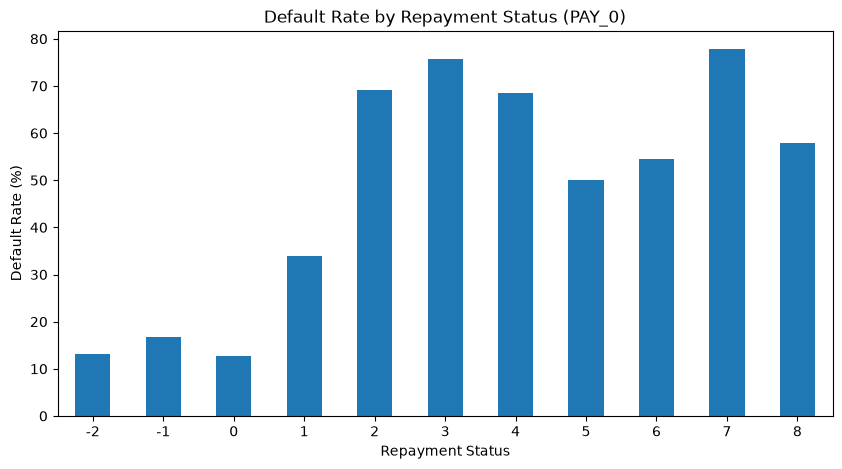

In [41]:
default_rate_by_pay0.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Repayment Status (PAY_0)")
plt.xlabel("Repayment Status")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [43]:
# You should now be able to visually answer:

# Q: Does default rate increase as repayment delinquency increases?

In [44]:
# What should you look for?

# Don't immediately conclude:
# -> "Higher PAY_0 causes default."

# That's not what this analysis proves.

# Instead say:
# => "There appears to be an association between repayment delinquency and default."

# This distinction is extremely important in data science.
# => Correlation/association ≠ causation

In [45]:
# we can say:
# -> Customers with higher delinquency levels tend to have higher default rates.

# We cannot say:
# -> Increasing PAY_0 causes customers to default.

# That's a causal claim, and this dataset isn't designed to establish causality.

In [46]:
# Repeat analyzing process for all 6 months pay

for col in customer_repays:
    print(f"\nDefault rate by {col}")
    
    result = (
        df.groupby(col)["default_payment_next_month"]
        .mean()
        .mul(100)
        .round(2)
    )
    
    print(result)


Default rate by pay_0
pay_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: default_payment_next_month, dtype: float64

Default rate by pay_2
pay_2
-2    18.27
-1    15.97
 0    15.91
 1    17.86
 2    55.61
 3    61.66
 4    50.51
 5    60.00
 6    75.00
 7    60.00
 8     0.00
Name: default_payment_next_month, dtype: float64

Default rate by pay_3
pay_3
-2    18.53
-1    15.59
 0    17.45
 1    25.00
 2    51.56
 3    57.50
 4    57.89
 5    57.14
 6    60.87
 7    81.48
 8    66.67
Name: default_payment_next_month, dtype: float64

Default rate by pay_4
pay_4
-2    19.25
-1    15.90
 0    18.33
 1    50.00
 2    52.33
 3    61.11
 4    66.67
 5    51.43
 6    40.00
 7    82.76
 8    50.00
Name: default_payment_next_month, dtype: float64

Default rate by pay_5
pay_5
-2     19.69
-1     16.19
 0     18.85
 2     54.19
 3     63.48
 4     60.71
 5     58.82
 6     75.00
 7     82.76
 8    100.00
N

In [47]:
default_rate_by_pay2 = (
    df.groupby("pay_2")["default_payment_next_month"]
      .mean()
      .mul(100)
      .round(2)
)

default_rate_by_pay2

pay_2
-2    18.27
-1    15.97
 0    15.91
 1    17.86
 2    55.61
 3    61.66
 4    50.51
 5    60.00
 6    75.00
 7    60.00
 8     0.00
Name: default_payment_next_month, dtype: float64

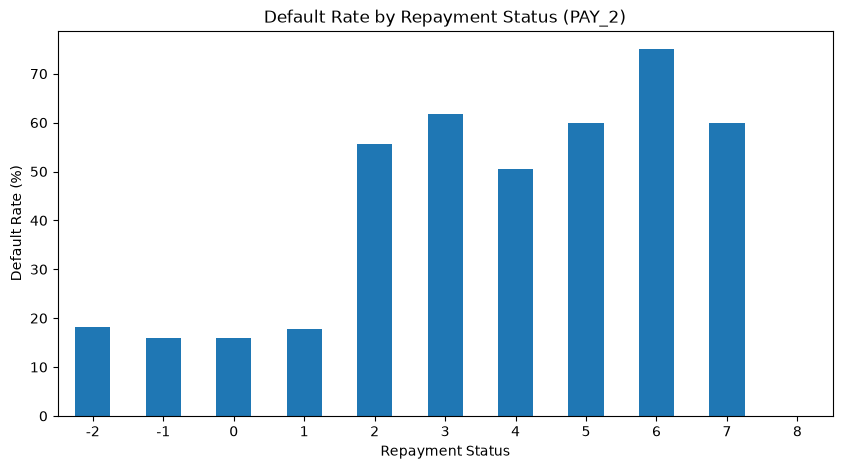

In [48]:
default_rate_by_pay2.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Repayment Status (PAY_2)")
plt.xlabel("Repayment Status")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [49]:
# EDA - 2. Distribution of repayment statuses

In [50]:
# Now let's answer a different question.

# Instead of:
# Q: "What percentage defaulted?"

# we ask:
# Q: "What repayment statuses are common among our customers?"

In [51]:
df["pay_6"].value_counts().sort_index()

pay_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int64

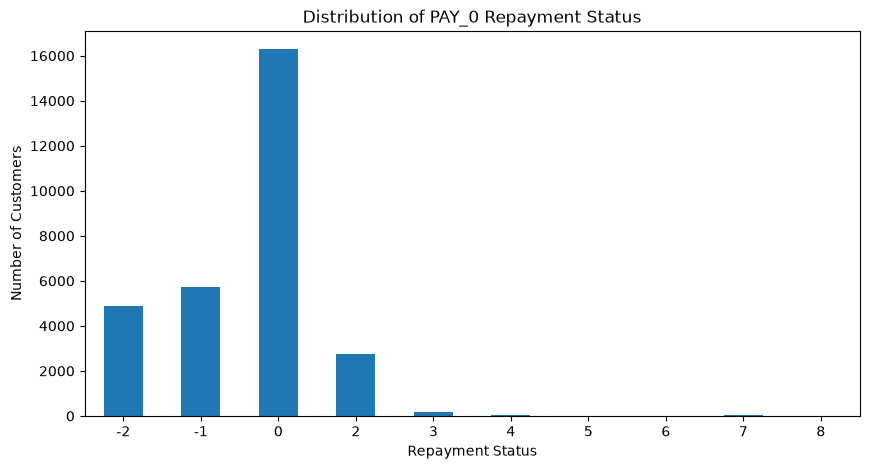

In [52]:
# Visualize

df["pay_6"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of PAY_0 Repayment Status")
plt.xlabel("Repayment Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [53]:
# The above tells you about the population distribution.

# Distribution:
# Q: How many customers are in each group?

# Default Rate:
# Q: What percentage of each group defaults?

In [54]:
# Distribution versus risk

In [55]:
# Default rate by number of delayed months

# Now we can create a more useful feature.

# Instead of looking at six individual columns independently, ask:
# Q: How many of the last six months showed delinquent repayment behavior? -> for a specific customer

In [56]:
# Create num_delayed_months

# Assuming:
# PAY >= 1 → delayed
# PAY <= 0 → not delayed

df["num_delayed_months"] = (df[customer_repays] > 0).sum(axis=1)

In [57]:
# Analyze default rate by delayed months

In [58]:
default_by_delayed_months = (
    df.groupby("num_delayed_months")["default_payment_next_month"]
      .mean()
      .mul(100)
      .round(2)
)

default_by_delayed_months

num_delayed_months
0    11.71
1    29.82
2    38.76
3    50.87
4    57.31
5    57.38
6    70.32
Name: default_payment_next_month, dtype: float64

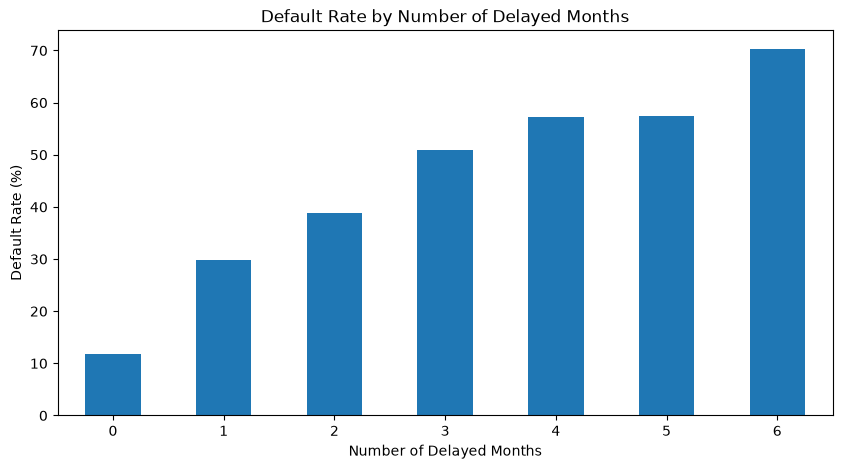

In [59]:
# Plot

default_by_delayed_months.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Number of Delayed Months")
plt.xlabel("Number of Delayed Months")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [60]:
# Now you're asking a much more financially meaningful question:

# Q: Does persistent repayment difficulty correspond to higher default risk?

In [61]:
# Average delinquency by default group:

# Now reverse the question:
# Instead of: delinquency → default

# Ask:
# default group → delinquency

In [62]:
df.groupby("default_payment_next_month")["num_delayed_months"].mean()

default_payment_next_month
0    0.504194
1    1.996082
Name: num_delayed_months, dtype: float64

In [63]:
# The above calculation result tells you:
# Customers who default tend to have experienced more repayment delays in the observed history.

# default = 0 -> 0.5 delayed months (not defaulted)
# default = 1 -> 2.0 delayed months (defaulted)

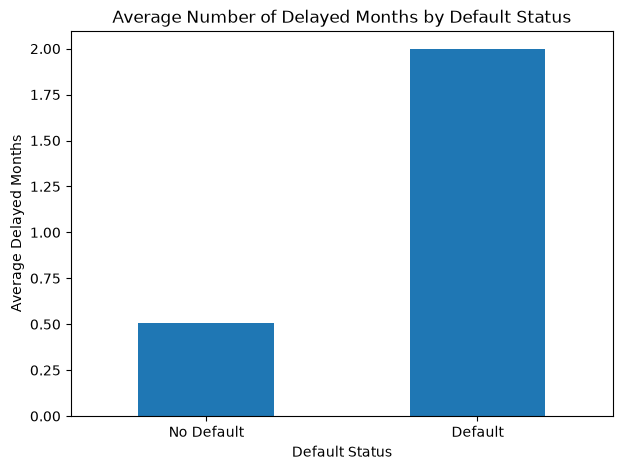

In [64]:
# A better visualization

df.groupby("default_payment_next_month")[
    "num_delayed_months"
].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Number of Delayed Months by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Average Delayed Months")
plt.xticks(
    ticks=[0, 1],
    labels=["No Default", "Default"],
    rotation=0
)

plt.show()

In [65]:
# EDA observations:

# 1. Repayment status is strongly associated with default risk.

# 2. Customers experiencing more severe delinquency tend to have higher default rates.

# 3. Customers who eventually default tend to have more delayed payments in their historical repayment record.

# 4. Recent repayment behavior may provide useful predictive information.

# 5. Repayment behavior should therefore be considered an important feature group for the ML model.

In [67]:
# EDA -> 3. Analyze credit limit

In [68]:
# df["limit_bal"]

# This represents the customer's credit limit.

# The question is:
# Q: Is credit limit associated with default risk?

In [69]:
df["limit_bal"].describe()

count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: limit_bal, dtype: float64

In [71]:
df["limit_bal"].max()

np.int64(1000000)

In [72]:
df["limit_bal"].min()

np.int64(10000)

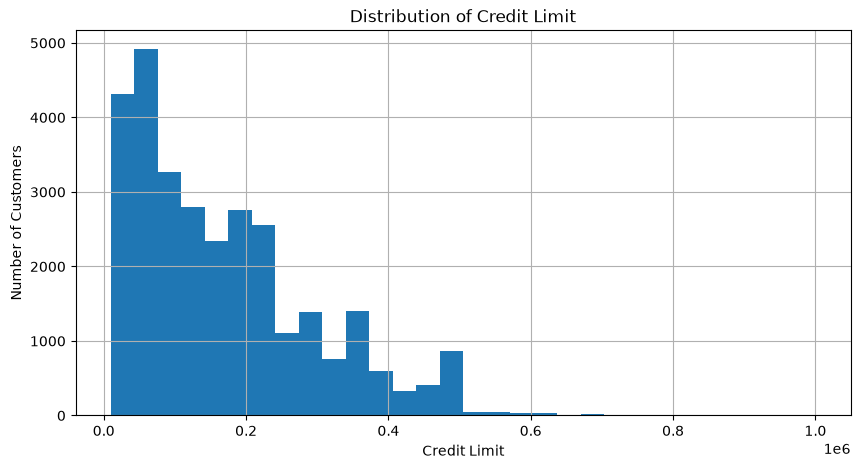

In [70]:
df["limit_bal"].hist(
    bins=30,
    figsize=(10, 5)
)

plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")
plt.show()

In [73]:
df["limit_bal"].skew()

np.float64(0.9928669605195428)

In [74]:
# Quantify Skewness

# ≈ 0 → approximately symmetric

# > 0 → right-skewed

# < 0 → left-skewed

In [75]:
# Skew Observation:
# So the result shows it is right-skewed (0.99 ~ 1 > 0)

In [76]:
# Log transformation

# A common transformation for positive, heavily right-skewed financial variables is:
# log(x)

# But your credit limit can be zero in principle, so a safer transformation is:
# log(1 + x)


In [77]:
df["log_limit_bal"] = np.log1p(df["limit_bal"])

In [78]:
df["log_limit_bal"].skew()

np.float64(-0.5134319757766014)

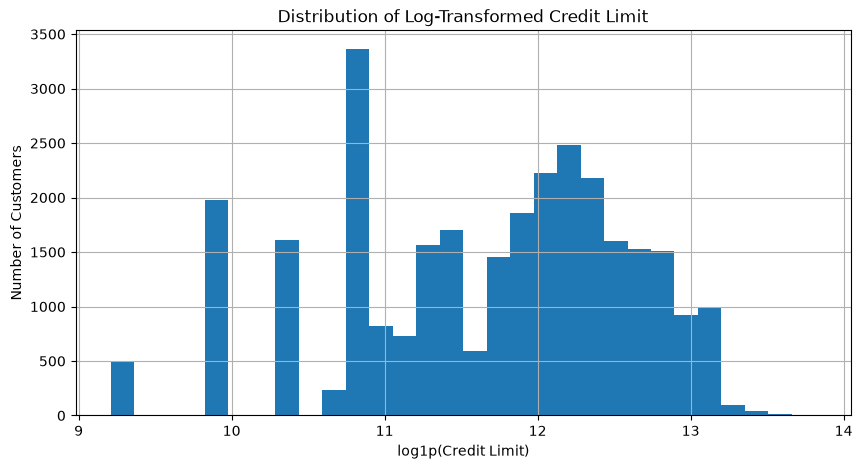

In [79]:
df["log_limit_bal"].hist(
    bins=30,
    figsize=(10, 5)
)

plt.title("Distribution of Log-Transformed Credit Limit")
plt.xlabel("log1p(Credit Limit)")
plt.ylabel("Number of Customers")
plt.show()

In [80]:
# But don't immediately add this to your final dataset
# Right now:
# log_limit_bal -> is an EDA experiment.

# You are asking:
# Q: Does transforming this feature make its distribution more manageable?

# Later, during feature engineering/modeling, you can decide whether it belongs in the final pipeline

In [81]:
# Default rate by credit-limit range

# Now we want to answer:
# Q: Are customers with lower credit limits more likely to default?

# A useful technique is binning.

In [82]:
# binning

df["limit_bal_group"] = pd.cut(
    df["limit_bal"],
    bins=5
)

df.groupby(
    "limit_bal_group",
    observed=True
)["default_payment_next_month"].mean()

limit_bal_group
(9010.0, 208000.0]       0.256110
(208000.0, 406000.0]     0.153492
(406000.0, 604000.0]     0.122319
(604000.0, 802000.0]     0.076923
(802000.0, 1000000.0]    0.000000
Name: default_payment_next_month, dtype: float64

In [83]:
# convert to pecentage

default_by_limit = (
    df.groupby("limit_bal_group", observed=True)
      ["default_payment_next_month"]
      .mean()
      .mul(100)
      .round(2)
)

default_by_limit

limit_bal_group
(9010.0, 208000.0]       25.61
(208000.0, 406000.0]     15.35
(406000.0, 604000.0]     12.23
(604000.0, 802000.0]      7.69
(802000.0, 1000000.0]     0.00
Name: default_payment_next_month, dtype: float64

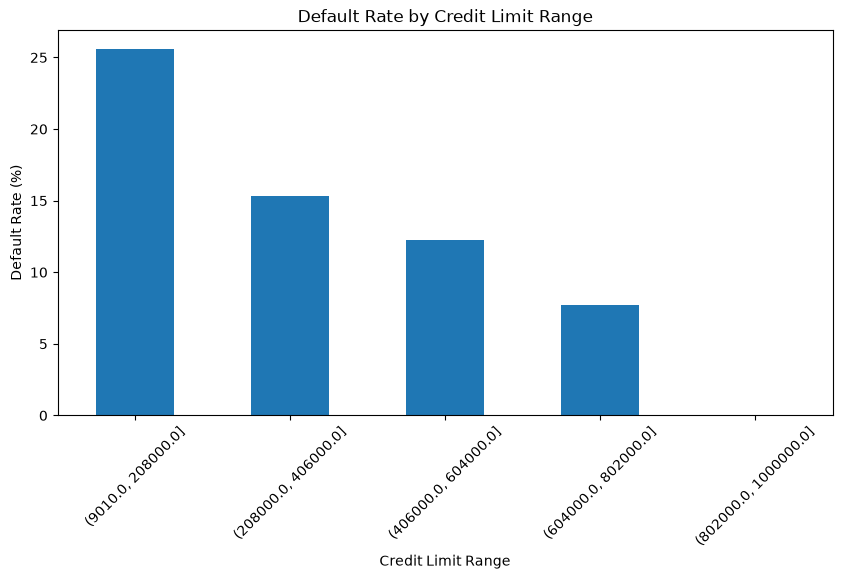

In [84]:
# visualize it:

default_by_limit.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Credit Limit Range")
plt.xlabel("Credit Limit Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [85]:
# Observations:
# Now you can see the default rate tends to:
# increase -> as the credit limit is lower (or decreases)
# decrease -> as the credit limit is higher (or increases)

In [86]:
# Compare credit limit between default groups

In [87]:
df.groupby(
    "default_payment_next_month"
)["limit_bal"].agg(
    ["mean", "median", "std"]
)

,mean,median,std
default_payment_next_month,,,
0,178099.726074,150000.0,131628.359660
1,130109.656420,90000.0,115378.540571


In [88]:
# Boxplot

# This helps you visually compare:

# No default vs Default

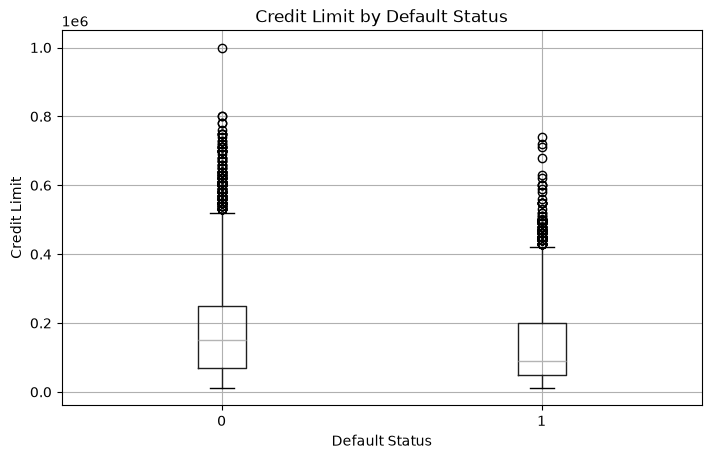

In [89]:
df.boxplot(
    column="limit_bal",
    by="default_payment_next_month",
    figsize=(8, 5)
)

plt.title("Credit Limit by Default Status")
plt.suptitle("")
plt.xlabel("Default Status")
plt.ylabel("Credit Limit")
plt.show()

In [90]:
# What you should conclude
# Again, don't assume the answer.

# Your analysis should determine:
# Q: Is credit limit meaningfully associated with default?

# Potential conclusion:

# Customers in lower credit-limit groups appear to have a higher
# default rate than customers in some higher credit-limit groups.

# However, credit limit alone does not explain default behavior,
# and the relationship may be influenced by other variables such
# as age, repayment behavior, and payment history.


# That's much more scientifically responsible than:
# "People with low credit limits default."

In [91]:
# Observation conclusion:

# The medians overlap quite a bit (both boxes overlap in the ~50,000–200,000 range), 
# so credit limit alone won't perfectly separate the classes — 
# but it's still one of the stronger features in this dataset and 
# worth keeping as a predictor in your model.

In [92]:
# EDA -> 4. Analyze bill/payment behavior

In [93]:
# Analyzing Billed-Amount and Payed-Bill-Amount means
# analyzing financial behavior over time.

# You are asking:
# Q: What does the customer's financial behavior look like?

In [94]:
# First define the two concepts:

# Bill Amount -> How much the customer was billed.

# Payment Amount -> How much the customer actually paid.

In [95]:
# Let's now create column groups

In [96]:
bill_columns = [
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "bill_amt4",
    "bill_amt5",
    "bill_amt6"
]

payment_columns = [
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_amt4",
    "pay_amt5",
    "pay_amt6"
]

In [ ]:
# 1. Average bill:

# This means:
# Average monthly bill across the six-month period.


In [99]:
df["avg_bill"] = df[bill_columns].mean(axis=1)

In [100]:
df["avg_bill"].describe()

count     30000.000000
mean      44976.945200
std       63260.721860
min      -56043.166667
25%        4781.333333
50%       21051.833333
75%       57104.416667
max      877313.833333
Name: avg_bill, dtype: float64

In [140]:
# 2. Maximum bill:

# Q: What is the customer's highest observed bill?

In [102]:
df["max_bill"] = df[bill_columns].max(axis=1)

df["max_bill"]

0          3913
1          3455
2         29239
3         49291
4         35835
          ...  
29995    208365
29996      8979
29997     20878
29998     78379
29999     49764
Name: max_bill, Length: 30000, dtype: int64

In [103]:
# 3. Minimum bill

df["min_bill"] = df[bill_columns].min(axis=1)

df["min_bill"]

0            0
1         1725
2        13559
3        28314
4         5670
         ...  
29995    15980
29996        0
29997     2758
29998    -1645
29999    15313
Name: min_bill, Length: 30000, dtype: int64

In [106]:
# 4. Bill variability:

# Q: Does the customer's bill remain relatively stable, or does it fluctuate significantly?

In [105]:
# Use standard deviation:

df["std_bill"] = df[bill_columns].std(axis=1)

df["std_bill"] 

0         1761.633219
1          637.967841
2         6064.518593
3        10565.793518
4        10668.590074
             ...     
29995    86697.439530
29996     3200.534247
29997     9354.149660
29998    32992.487323
29999    13434.377500
Name: std_bill, Length: 30000, dtype: float64

In [108]:
# Analysis:

# Low standard deviation — what it shows:
# A low std_bill means the customer's bill amounts are stable and consistent over the 6 months.
# E.g., customer 1 with std_bill = 637.97 roughly bills around the same amount every month (e.g., ~11,400 ± small fluctuations).
# Financially, this suggests: steady, predictable spending behavior — possibly fixed subscriptions, routine usage, or a customer in a stable financial routine.
# For a model, it's a "low-volatility" signal — spending that doesn't spike or collapse.

# High standard deviation — what it shows
# A high std_bill means the customer's bills swing widely from month to month.
# E.g., customer 29,995 with std_bill = 86,697 has bills that vary by tens of thousands of NT dollars month to month — huge ups and downs.
# Financially, this can indicate:
# Irregular income or spending (e.g., commission-based earners, seasonal spending, big one-off purchases)
# Financial stress or instability — large swings often precede payment trouble
# Possible balance transfers, lump-sum payments, or card-limit behavior reflected in the statement
# For a model, it's a "high-volatility" signal.

In [109]:
# Important caveat for this dataset:

# A high std doesn't always mean financial trouble — sometimes it just means 
# the customer spends a lot overall (a rich customer's bills may vary more in absolute terms but be trivially affordable for them). 
# So std_bill alone can be misleading. 

In [139]:
# 1. Average payment

In [110]:
df["avg_payment"] = df[payment_columns].mean(axis=1)

df["avg_payment"]

0          114.833333
1          833.333333
2         1836.333333
3         1398.000000
4         9841.500000
             ...     
29995     7091.666667
29996     2415.000000
29997     5216.666667
29998    24530.166667
29999     1384.666667
Name: avg_payment, Length: 30000, dtype: float64

In [138]:
# 2. Maximum payment

In [111]:
df["max_payment"] = df[payment_columns].max(axis=1)

df["max_payment"] 

0          689
1         2000
2         5000
3         2019
4        36681
         ...  
29995    20000
29996     8998
29997    22000
29998    85900
29999     2078
Name: max_payment, Length: 30000, dtype: int64

In [112]:
# 3. Minimum payment

In [113]:
df["min_payment"] = df[payment_columns].min(axis=1)

df["min_payment"]

0           0
1           0
2        1000
3        1000
4         679
         ... 
29995    1000
29996       0
29997       0
29998    1178
29999    1000
Name: min_payment, Length: 30000, dtype: int64

In [137]:
# 4. Payment variability

In [114]:
df["std_payment"] = df[payment_columns].std(axis=1)

df["std_payment"]

0          281.283072
1          752.772653
2         1569.815488
3          478.058155
4        13786.230736
             ...     
29995     6794.318234
29996     3515.523859
29997     8390.093365
29998    36314.167188
29999      468.865297
Name: std_payment, Length: 30000, dtype: float64

In [116]:
# Payment-to-bill relationship

# Calculate monthly payment ratio

In [ ]:
df["payment_ratio_1"] = (
    df["pay_amt1"] /
    df["bill_amt1"].replace(0, np.nan)
)

for i in range(1, 7):
    bill_col = f"bill_amt{i}"
    pay_col = f"pay_amt{i}"
    
    df[f"payment_ratio_{i}"] = (
        df[pay_col] /
        df[bill_col].replace(0, np.nan)
    )

# The replace(0, np.nan) prevents division by zero.

In [136]:
# Average payment ratio

In [119]:
ratio_columns = [
    f"payment_ratio_{i}"
    for i in range(1, 7)
]

df["avg_payment_ratio"] = df[ratio_columns].mean(axis=1)

In [135]:
# Now you have:
# Average proportion of the customer's bill that they paid.

# This is a potentially powerful financial-behavior feature.

In [134]:
# Analyze payment ratio by default

In [121]:
df.groupby(
    "default_payment_next_month"
)["avg_payment_ratio"].mean()

default_payment_next_month
0   -2.442579
1   -1.672784
Name: avg_payment_ratio, dtype: float64

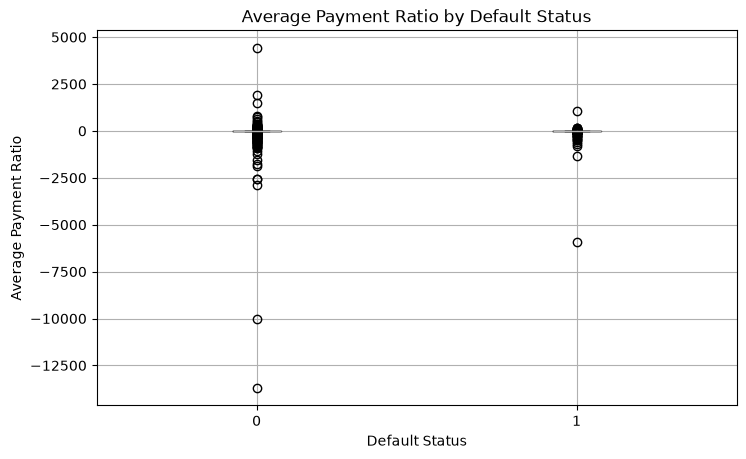

In [122]:
# visualize

df.boxplot(
    column="avg_payment_ratio",
    by="default_payment_next_month",
    figsize=(8, 5)
)

plt.title("Average Payment Ratio by Default Status")
plt.suptitle("")
plt.xlabel("Default Status")
plt.ylabel("Average Payment Ratio")
plt.show()

In [129]:
# You are now asking:
# Q: Do customers who default tend to pay a smaller proportion of their bills?

# That is a much more meaningful fintech question.

In [128]:
# Month-to-month Bill payment changes

In [124]:
bill_change_columns = []

for i in range(1, 6):
    current = f"bill_amt{i}"
    previous = f"bill_amt{i+1}"
    new_col = f"bill_change_{i}_{i+1}"
    
    df[new_col] = df[current] - df[previous]
    bill_change_columns.append(new_col)

In [125]:
df["avg_bill_change"] = df[bill_change_columns].mean(axis=1)

In [127]:
# This tells us approximately:

# Is the customer's bill increasing or decreasing over time?

In [133]:
# Payment trend

In [130]:
payment_change_columns = []

for i in range(1, 6):
    current = f"pay_amt{i}"
    previous = f"pay_amt{i+1}"
    
    new_col = f"payment_change_{i}_{i+1}"
    
    df[new_col] = df[current] - df[previous]
    payment_change_columns.append(new_col)

In [131]:
df["avg_payment_change"] = (
    df[payment_change_columns].mean(axis=1)
)

In [132]:
df.head()

,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_change_3_4,bill_change_4_5,bill_change_5_6,avg_bill_change,payment_change_1_2,payment_change_2_3,payment_change_3_4,payment_change_4_5,payment_change_5_6,avg_payment_change
0,1,20000,2,2,1,24,2,2,-1,-1,...,689,0,0,782.6,-689,689,0,0,0,0.0
1,2,120000,2,2,2,26,-1,2,0,0,...,-590,-183,194,-115.8,-1000,0,0,1000,-2000,-400.0
2,3,90000,2,2,2,34,0,0,0,0,...,-772,-617,-601,2738.0,18,500,0,0,-4000,-696.4
3,4,50000,2,2,1,37,0,0,0,0,...,20977,-645,-588,3488.6,-19,819,100,31,69,200.0
4,5,50000,1,2,1,57,-1,0,-1,0,...,14895,1794,15,-2102.8,-34681,26681,1000,8311,10,264.2


In [141]:
df.columns

Index(['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0',
       'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6',
       'default_payment_next_month', 'num_delayed_months', 'log_limit_bal',
       'limit_bal_group', 'avg_bill', 'max_bill', 'min_bill', 'std_bill',
       'avg_payment', 'max_payment', 'min_payment', 'std_payment',
       'payment_ratio_1', 'payment_ratio_2', 'payment_ratio_3',
       'payment_ratio_4', 'payment_ratio_5', 'payment_ratio_6',
       'avg_payment_ratio', 'bill_change_1_2', 'bill_change_2_3',
       'bill_change_3_4', 'bill_change_4_5', 'bill_change_5_6',
       'avg_bill_change', 'payment_change_1_2', 'payment_change_2_3',
       'payment_change_3_4', 'payment_change_4_5', 'payment_change_5_6',
       'avg_payment_change'],
      dtype='str')